# 03 — Explorative Datenanalyse

Geschäftsorientierte Analyse des aufbereiteten Policy-Datensatzes.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

PROJECT_ROOT = (
    Path.cwd().parent
    if Path.cwd().name == "notebooks"
    else Path.cwd()
)

DATA_FILE = PROJECT_ROOT / "data" / "processed" / "policy_curated.pq"

print("File exists:", DATA_FILE.exists())

df = pd.read_parquet(DATA_FILE)

print("Shape:", df.shape)

File exists: True
Shape: (678013, 25)


## 1. Überblick über den aufbereiteten Datensatz

Zunächst werden Struktur, Spalten und erste Beobachtungen geprüft.

In [2]:
df.head()

,IDpol,ClaimNb,Exposure,Area,VehPower,VehAge,DrivAge,BonusMalus,VehBrand,VehGas,...,claim_record_count,claim_count_mismatch,missing_severity,observed_claim_frequency,observed_severity,observed_pure_premium,driver_age_group,vehicle_age_group,bonus_malus_segment,log_density
0,1.0,1,0.10,D,5,0,55,50,B12,Regular,...,NaN,False,True,10.000000,NaN,NaN,55-64,0-2,50,7.104965
1,3.0,1,0.77,D,5,0,55,50,B12,Regular,...,NaN,False,True,1.298701,NaN,NaN,55-64,0-2,50,7.104965
2,5.0,1,0.75,B,6,2,52,50,B12,Diesel,...,NaN,False,True,1.333333,NaN,NaN,45-54,0-2,50,4.007333
3,10.0,1,0.09,B,7,0,46,50,B12,Diesel,...,NaN,False,True,11.111111,NaN,NaN,45-54,0-2,50,4.343805
4,11.0,1,0.84,B,7,0,46,50,B12,Diesel,...,NaN,False,True,1.190476,NaN,NaN,45-54,0-2,50,4.343805


### Spaltenübersicht

Alle verfügbaren Spalten des aufbereiteten Datensatzes werden angezeigt.

In [3]:
df.columns.tolist()

['IDpol',
 'ClaimNb',
 'Exposure',
 'Area',
 'VehPower',
 'VehAge',
 'DrivAge',
 'BonusMalus',
 'VehBrand',
 'VehGas',
 'Density',
 'Region',
 'exposure_capped',
 'high_claim_count',
 'total_claim_amount',
 'claim_record_count',
 'claim_count_mismatch',
 'missing_severity',
 'observed_claim_frequency',
 'observed_severity',
 'observed_pure_premium',
 'driver_age_group',
 'vehicle_age_group',
 'bonus_malus_segment',
 'log_density']

**Hinweis:** Der Rohdatensatz wurde bereinigt, mit Severity-Informationen angereichert und um Data-Quality-Flags sowie relevante Analyse- und Modellierungsfeatures erweitert.

### Struktur und Datentypen

Die Struktur und Datentypen des aufbereiteten Datensatzes werden überprüft.

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 678013 entries, 0 to 678012
Data columns (total 25 columns):
 #   Column                    Non-Null Count   Dtype   
---  ------                    --------------   -----   
 0   IDpol                     678013 non-null  float64 
 1   ClaimNb                   678013 non-null  uint8   
 2   Exposure                  678013 non-null  float64 
 3   Area                      678013 non-null  category
 4   VehPower                  678013 non-null  uint8   
 5   VehAge                    678013 non-null  uint8   
 6   DrivAge                   678013 non-null  uint8   
 7   BonusMalus                678013 non-null  uint8   
 8   VehBrand                  678013 non-null  category
 9   VehGas                    678013 non-null  object  
 10  Density                   678013 non-null  float64 
 11  Region                    678013 non-null  category
 12  exposure_capped           678013 non-null  bool    
 13  high_claim_count          678

**Hinweis:** Fehlende Werte in severity-basierten Merkmalen sind teilweise fachlich bedingt und werden nicht automatisch als Datenfehler interpretiert.

### Fehlende Werte

Die fehlenden Werte im aufbereiteten Datensatz werden überprüft.

In [5]:
df.isna().sum()

IDpol                            0
ClaimNb                          0
Exposure                         0
Area                             0
VehPower                         0
VehAge                           0
DrivAge                          0
BonusMalus                       0
VehBrand                         0
VehGas                           0
Density                          0
Region                           0
exposure_capped                  0
high_claim_count                 0
total_claim_amount            9116
claim_record_count            9116
claim_count_mismatch             0
missing_severity                 0
observed_claim_frequency         0
observed_severity           653069
observed_pure_premium         9116
driver_age_group                 0
vehicle_age_group                0
bonus_malus_segment              0
log_density                      0
dtype: int64

In [6]:
df.isna().sum()[df.isna().sum() > 0]

total_claim_amount         9116
claim_record_count         9116
observed_severity        653069
observed_pure_premium      9116
dtype: int64

**Ergebnis:** Die fehlenden Werte sind fachlich erklärbar. Bei 9.116 Policen fehlen Severity-Informationen; zusätzlich ist die beobachtete Severity bei schadenfreien Policen nicht definiert.

### Duplikate im aufbereiteten Datensatz

Es wird geprüft, ob durch die Datenaufbereitung doppelte Policy-Einträge entstanden sind.

In [7]:
print("Exact duplicates:", df.duplicated().sum())
print("Duplicate Policy IDs:", df["IDpol"].duplicated().sum())

Exact duplicates: 0
Duplicate Policy IDs: 0


**Ergebnis:** Im aufbereiteten Datensatz wurden weder exakte Duplikate noch doppelte Policy-IDs gefunden.

### Deskriptive Statistik

Die wichtigsten numerischen Merkmale werden zusammenfassend betrachtet.

In [8]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
IDpol,678013.0,2.621857e+06,1.641783e+06,1.000000,1.157951e+06,2.272152e+06,4.046274e+06,6.114330e+06
ClaimNb,678013.0,5.324677e-02,2.401173e-01,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,1.600000e+01
Exposure,678013.0,5.285446e-01,3.640807e-01,0.002732,1.800000e-01,4.900000e-01,9.900000e-01,1.000000e+00
VehPower,678013.0,6.454631e+00,2.050906e+00,4.000000,5.000000e+00,6.000000e+00,7.000000e+00,1.500000e+01
VehAge,678013.0,7.044265e+00,5.666232e+00,0.000000,2.000000e+00,6.000000e+00,1.100000e+01,1.000000e+02
DrivAge,678013.0,4.549912e+01,1.413744e+01,18.000000,3.400000e+01,4.400000e+01,5.500000e+01,1.000000e+02
BonusMalus,678013.0,5.976150e+01,1.563666e+01,50.000000,5.000000e+01,5.000000e+01,6.400000e+01,2.300000e+02
Density,678013.0,1.792422e+03,3.958647e+03,1.000000,9.200000e+01,3.930000e+02,1.658000e+03,2.700000e+04
total_claim_amount,668897.0,8.956419e+01,5.861986e+03,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,4.075401e+06
claim_record_count,668897.0,3.953374e-02,2.085221e-01,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,1.600000e+01


**Ergebnis:** Die deskriptiven Statistiken zeigen stark rechtsschiefe Verteilungen bei Schadenhöhe, Pure Premium und Density. Auffällige Extremwerte bleiben erhalten und werden in den weiteren Analysen berücksichtigt.

### Prüfung der Feature-Gruppen

Die definierten Alters- und Bonus-Malus-Gruppen werden überprüft.

In [9]:
df.groupby(
    "driver_age_group",
    observed=True
)["DrivAge"].agg(["min", "max", "count"])

,min,max,count
driver_age_group,,,
18-24,18,24,30198
25-34,25,34,140947
35-44,35,44,170578
45-54,45,54,164034
55-64,55,64,99094
65-74,65,74,50821
75+,75,100,22341


**Ergebnis:** Die Fahrer werden in nachvollziehbare Altersgruppen eingeteilt. Junge Fahrer werden separat betrachtet, anschließend folgen überwiegend Zehnjahresintervalle.

In [10]:
df.groupby(
    "vehicle_age_group",
    observed=True
)["VehAge"].agg(["min", "max", "count"])

,min,max,count
vehicle_age_group,,,
0-2,0,2,188147
3-5,3,5,132490
6-10,6,10,171594
11-15,11,15,134063
16-20,16,20,43397
21+,21,100,8322


**Ergebnis:** Das Fahrzeugalter wird in praxisnahe Gruppen unterteilt. Sehr junge Fahrzeuge werden separat betrachtet, ältere Fahrzeuge in breiteren Intervallen zusammengefasst.

In [11]:
df.groupby(
    "bonus_malus_segment",
    observed=True
)["BonusMalus"].agg(["min", "max", "count"])

,min,max,count
bonus_malus_segment,,,
50,50,50,384156
51-64,51,64,124711
65-79,65,79,70404
80-99,80,99,71418
100+,100,230,27324


**Ergebnis:** Der Wert 50 bildet aufgrund seiner hohen Häufigkeit eine eigene Gruppe. Höhere Bonus-Malus-Werte werden in schrittweise ansteigenden Segmenten zusammengefasst.

## 2. Fahrer-Alter und Schadenhäufigkeit

Die Schadenhäufigkeit wird nach Fahrer-Altersgruppen untersucht.

In [12]:
driver_age_summary = (
    df.groupby("driver_age_group", observed=True)
    .agg(
        policies=("IDpol", "count"),
        exposure=("Exposure", "sum"),
        claims=("ClaimNb", "sum"),
    )
)

driver_age_summary["claim_frequency"] = (
    driver_age_summary["claims"]
    / driver_age_summary["exposure"]
)

driver_age_summary

,policies,exposure,claims,claim_frequency
driver_age_group,,,,
18-24,30198,12488.891085,2364,0.189288
25-34,140947,64572.594437,6396,0.099051
35-44,170578,87349.662517,8145,0.093246
45-54,164034,89814.326483,9513,0.105919
55-64,99094,56157.391112,5124,0.091244
65-74,50821,32197.690968,2986,0.092740
75+,22341,15779.548863,1574,0.099749


### Visualisierung der Schadenhäufigkeit nach Fahrer-Alter

Die Schadenhäufigkeit wird nach Altersgruppen grafisch verglichen.

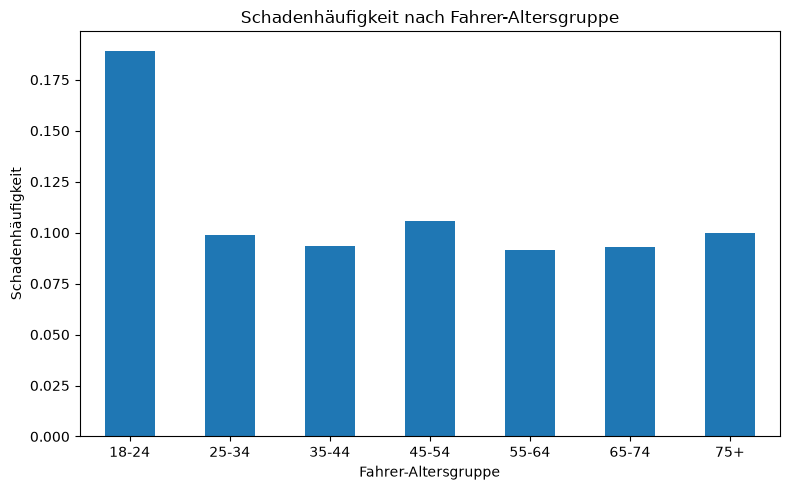

In [13]:
driver_age_summary["claim_frequency"].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Schadenhäufigkeit nach Fahrer-Altersgruppe")
plt.xlabel("Fahrer-Altersgruppe")
plt.ylabel("Schadenhäufigkeit")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Ergebnis:** Die Fahrergruppe 18–24 weist mit Abstand die höchste Schadenhäufigkeit auf. Die übrigen Altersgruppen liegen deutlich näher beieinander.

## 3. Fahrzeugalter und Schadenhäufigkeit

Die Schadenhäufigkeit wird nach Fahrzeugaltersgruppen untersucht.

In [14]:
vehicle_age_summary = (
    df.groupby("vehicle_age_group", observed=True)
    .agg(
        policies=("IDpol", "count"),
        exposure=("Exposure", "sum"),
        claims=("ClaimNb", "sum"),
    )
)

vehicle_age_summary["claim_frequency"] = (
    vehicle_age_summary["claims"]
    / vehicle_age_summary["exposure"]
)

vehicle_age_summary

,policies,exposure,claims,claim_frequency
vehicle_age_group,,,,
0-2,188147,79137.945348,10904,0.137785
3-5,132490,72021.113776,6743,0.093625
6-10,171594,98974.296361,9846,0.099480
11-15,134063,77954.995407,6648,0.085280
16-20,43397,25127.168607,1685,0.067059
21+,8322,5144.585965,276,0.053649


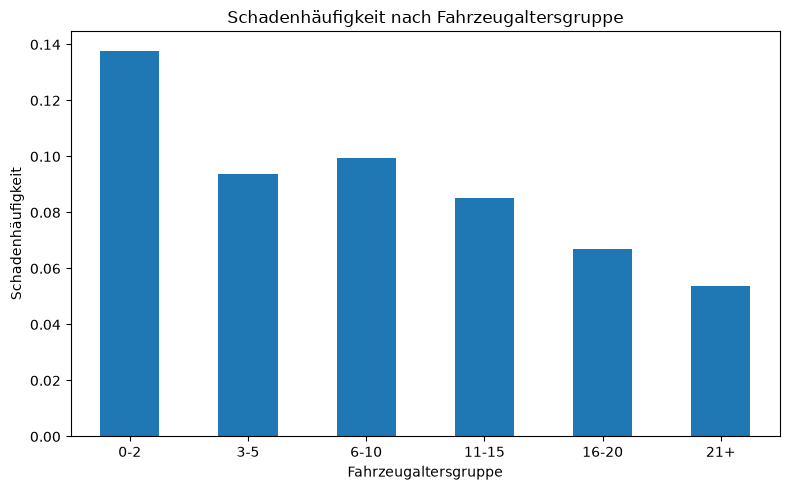

In [15]:
vehicle_age_summary["claim_frequency"].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Schadenhäufigkeit nach Fahrzeugaltersgruppe")
plt.xlabel("Fahrzeugaltersgruppe")
plt.ylabel("Schadenhäufigkeit")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Ergebnis:** Fahrzeuge im Alter von 0–2 Jahren weisen die höchste Schadenhäufigkeit auf. Mit zunehmendem Fahrzeugalter zeigt sich insgesamt ein rückläufiger Trend, auch wenn dieser nicht vollständig monoton verläuft.

## 4. Fahrzeugleistung und Schadenhäufigkeit

Die Schadenhäufigkeit wird nach Fahrzeugleistung untersucht.

In [16]:
vehicle_power_summary = (
    df.groupby("VehPower", observed=True)
    .agg(
        policies=("IDpol", "count"),
        exposure=("Exposure", "sum"),
        claims=("ClaimNb", "sum"),
    )
)

vehicle_power_summary["claim_frequency"] = (
    vehicle_power_summary["claims"]
    / vehicle_power_summary["exposure"]
)

vehicle_power_summary

,policies,exposure,claims,claim_frequency
VehPower,,,,
4,115349,60055.327304,5699,0.094896
5,124821,68148.128821,7278,0.106797
6,148976,82497.590172,8381,0.101591
7,145401,77919.746700,7627,0.097883
8,46956,22673.966305,1922,0.084767
9,30085,15338.643656,1754,0.114352
10,31354,15367.090824,1789,0.116418
11,18352,8491.308452,897,0.105637
12,8214,3790.798343,359,0.094703


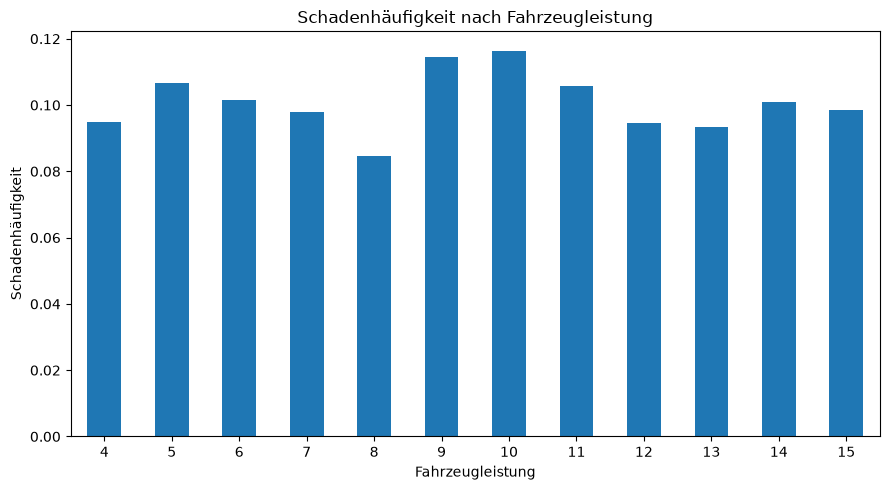

In [17]:
vehicle_power_summary["claim_frequency"].plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Schadenhäufigkeit nach Fahrzeugleistung")
plt.xlabel("Fahrzeugleistung")
plt.ylabel("Schadenhäufigkeit")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Ergebnis:** Die Schadenhäufigkeit variiert je nach Fahrzeugleistung, zeigt jedoch keinen klaren monotonen Trend. Besonders die Leistungsgruppen 9 und 10 weisen höhere Werte auf.

## 5. Bonus-Malus und Schadenhäufigkeit

Die Schadenhäufigkeit wird nach Bonus-Malus-Segmenten untersucht.

In [18]:
bonus_malus_summary = (
    df.groupby("bonus_malus_segment", observed=True)
    .agg(
        policies=("IDpol", "count"),
        exposure=("Exposure", "sum"),
        claims=("ClaimNb", "sum"),
    )
)

bonus_malus_summary["claim_frequency"] = (
    bonus_malus_summary["claims"]
    / bonus_malus_summary["exposure"]
)

bonus_malus_summary

,policies,exposure,claims,claim_frequency
bonus_malus_segment,,,,
50,384156,225152.650903,18056,0.080194
51-64,124711,62427.661755,6792,0.108798
65-79,70404,31159.068718,3926,0.125999
80-99,71418,29809.491727,4265,0.143075
100+,27324,9811.232359,3063,0.312193


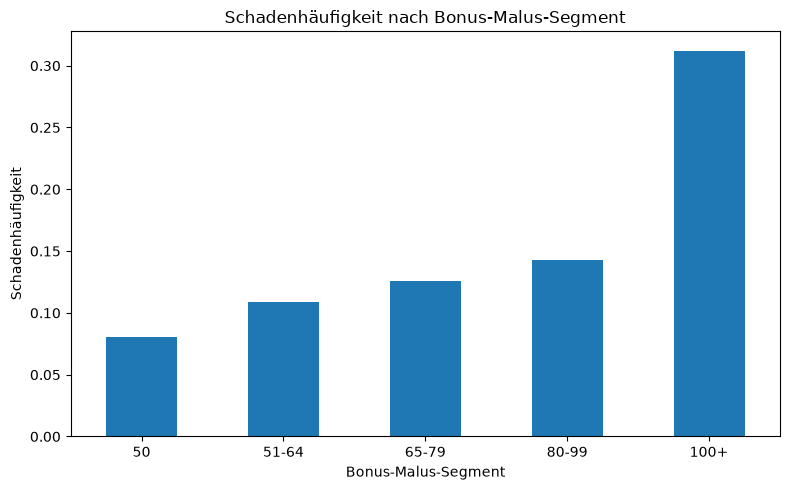

In [19]:
bonus_malus_summary["claim_frequency"].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Schadenhäufigkeit nach Bonus-Malus-Segment")
plt.xlabel("Bonus-Malus-Segment")
plt.ylabel("Schadenhäufigkeit")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Ergebnis:** Mit steigenden Bonus-Malus-Werten nimmt die Schadenhäufigkeit deutlich zu. Das Segment 100+ weist mit Abstand die höchste Schadenhäufigkeit auf.

## 6. Gebietsklasse und Schadenhäufigkeit

Die Schadenhäufigkeit wird nach Gebietsklassen untersucht.

In [20]:
area_summary = (
    df.groupby("Area", observed=True)
    .agg(
        policies=("IDpol", "count"),
        exposure=("Exposure", "sum"),
        claims=("ClaimNb", "sum"),
    )
)

area_summary["claim_frequency"] = (
    area_summary["claims"]
    / area_summary["exposure"]
)

area_summary

,policies,exposure,claims,claim_frequency
Area,,,,
A,103957,61956.827712,5063,0.081718
B,75459,43001.823931,3800,0.088368
C,191880,104402.523785,9875,0.094586
D,151596,77087.801692,8428,0.109330
E,137167,63785.694270,7805,0.122363
F,17954,8125.434074,1131,0.139193


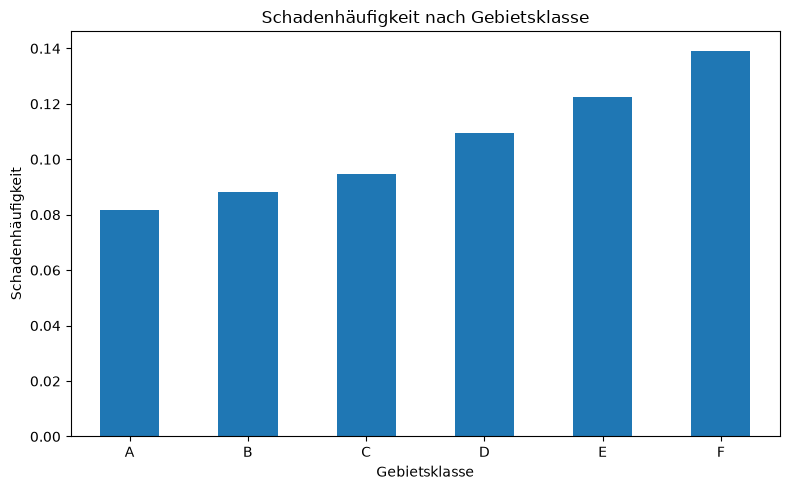

In [21]:
area_summary["claim_frequency"].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Schadenhäufigkeit nach Gebietsklasse")
plt.xlabel("Gebietsklasse")
plt.ylabel("Schadenhäufigkeit")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Ergebnis:** Mit steigender Gebietsklasse nimmt die Schadenhäufigkeit kontinuierlich zu. Die Klasse F weist die höchste, die Klasse A die niedrigste Schadenhäufigkeit auf.

### Region und Schadenhäufigkeit

Die Schadenhäufigkeit wird nach Regionen untersucht.

In [22]:
region_summary = (
    df.groupby("Region", observed=True)
    .agg(
        policies=("IDpol", "count"),
        exposure=("Exposure", "sum"),
        claims=("ClaimNb", "sum"),
    )
)

region_summary["claim_frequency"] = (
    region_summary["claims"]
    / region_summary["exposure"]
)

region_summary.sort_values(
    "claim_frequency",
    ascending=False
)

,policies,exposure,claims,claim_frequency
Region,,,,
R94,4516,1765.935399,247,0.139869
R21,3026,1204.341509,160,0.132853
R11,69791,30198.131954,3978,0.131730
R22,7994,3572.840221,439,0.122871
R82,84752,45332.587286,5032,0.111002
R42,2200,1208.635823,133,0.110041
R93,79315,35748.981015,3907,0.109290
R74,4567,2395.734542,259,0.108109
R91,35805,14710.624177,1547,0.105162


### Visualisierung nach Region

Die regionalen Unterschiede der Schadenhäufigkeit werden grafisch dargestellt.

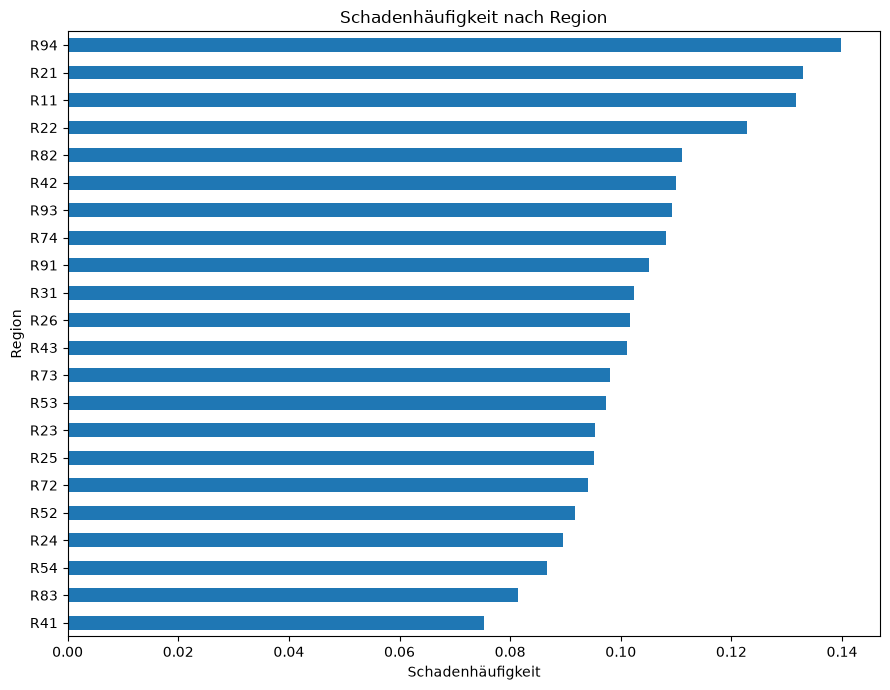

In [23]:
region_plot = region_summary.sort_values(
    "claim_frequency",
    ascending=True
)

region_plot["claim_frequency"].plot(
    kind="barh",
    figsize=(9, 7)
)

plt.title("Schadenhäufigkeit nach Region")
plt.xlabel("Schadenhäufigkeit")
plt.ylabel("Region")
plt.tight_layout()
plt.show()

**Ergebnis:** Zwischen den Regionen bestehen deutliche Unterschiede in der Schadenhäufigkeit. R94, R21 und R11 weisen die höchsten Werte auf, während R41 zu den niedrigsten gehört.

### Bevölkerungsdichte und Schadenhäufigkeit

Die Schadenhäufigkeit wird nach Dichteklassen untersucht.

In [24]:
df["density_group"] = pd.qcut(
    df["Density"],
    q=5,
    duplicates="drop"
)

density_summary = (
    df.groupby("density_group", observed=True)
    .agg(
        policies=("IDpol", "count"),
        exposure=("Exposure", "sum"),
        claims=("ClaimNb", "sum"),
    )
)

density_summary["claim_frequency"] = (
    density_summary["claims"]
    / density_summary["exposure"]
)

density_summary

,policies,exposure,claims,claim_frequency
density_group,,,,
"(0.999, 67.0]",137340,81391.989565,6753,0.082969
"(67.0, 214.0]",134178,74079.359570,6743,0.091024
"(214.0, 716.0]",135398,72007.451585,7091,0.098476
"(716.0, 2715.0]",137845,69456.813925,7855,0.113092
"(2715.0, 27000.0]",133252,61424.490818,7660,0.124706


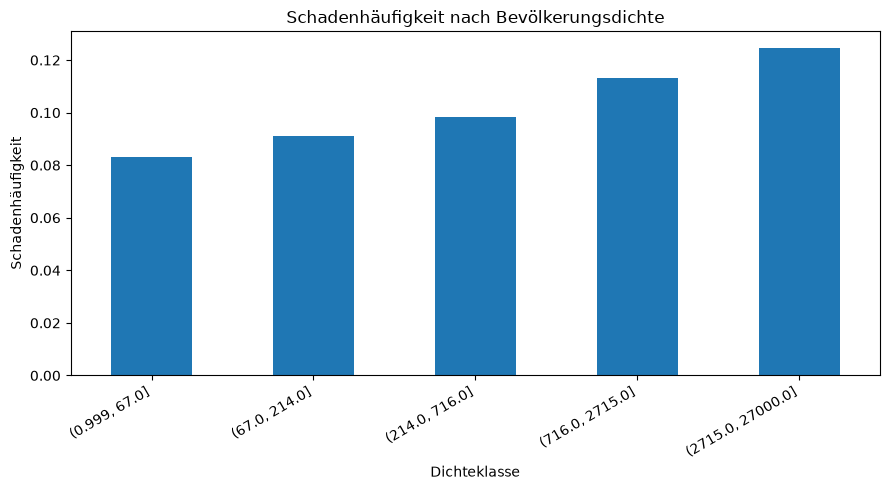

In [25]:
density_summary["claim_frequency"].plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Schadenhäufigkeit nach Bevölkerungsdichte")
plt.xlabel("Dichteklasse")
plt.ylabel("Schadenhäufigkeit")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

**Ergebnis:** Mit steigender Bevölkerungsdichte nimmt die Schadenhäufigkeit kontinuierlich zu. Dicht besiedelte Gebiete weisen höhere Schadenhäufigkeiten auf.

## 7. Kraftstoffart und Schadenhäufigkeit

Die Schadenhäufigkeit wird nach Kraftstoffart untersucht.

In [26]:
fuel_summary = (
    df.groupby("VehGas", observed=True)
    .agg(
        policies=("IDpol", "count"),
        exposure=("Exposure", "sum"),
        claims=("ClaimNb", "sum"),
    )
)

fuel_summary["claim_frequency"] = (
    fuel_summary["claims"]
    / fuel_summary["exposure"]
)

fuel_summary

,policies,exposure,claims,claim_frequency
VehGas,,,,
Diesel,332136,170587.553127,16648,0.097592
Regular,345877,187772.552336,19454,0.103604


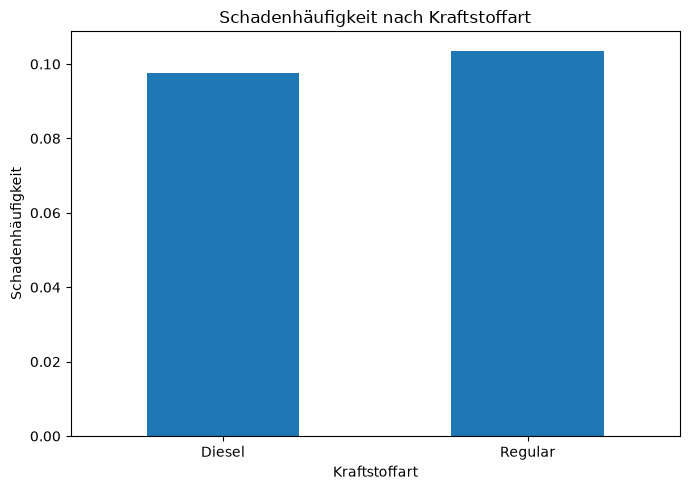

In [27]:
fuel_summary["claim_frequency"].plot(
    kind="bar",
    figsize=(7, 5)
)

plt.title("Schadenhäufigkeit nach Kraftstoffart")
plt.xlabel("Kraftstoffart")
plt.ylabel("Schadenhäufigkeit")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Ergebnis:** Fahrzeuge mit Regular-Antrieb weisen eine leicht höhere Schadenhäufigkeit als Diesel-Fahrzeuge auf. Der Unterschied ist jedoch vergleichsweise gering.

## 8. Verteilung der Schadenhöhen

Die Verteilung der einzelnen Schadenbeträge wird mit Fokus auf Extremwerte untersucht.

In [28]:
SEVERITY_FILE = (
    PROJECT_ROOT
    / "data"
    / "raw"
    / "freMTPL2sev.pq"
)

severity_df = pd.read_parquet(SEVERITY_FILE)

severity_df["ClaimAmount"].describe(
    percentiles=[0.90, 0.95, 0.99, 0.999]
)

count    2.663900e+04
mean     2.278536e+03
std      2.929748e+04
min      1.000000e+00
50%      1.172000e+03
90%      2.799072e+03
95%      4.861685e+03
99%      1.679370e+04
99.9%    1.627844e+05
max      4.075401e+06
Name: ClaimAmount, dtype: float64

### Verteilung mit logarithmischer Skala

Die Schadenbeträge werden auf einer logarithmischen Skala dargestellt, um die starke Rechtsschiefe sichtbar zu machen.

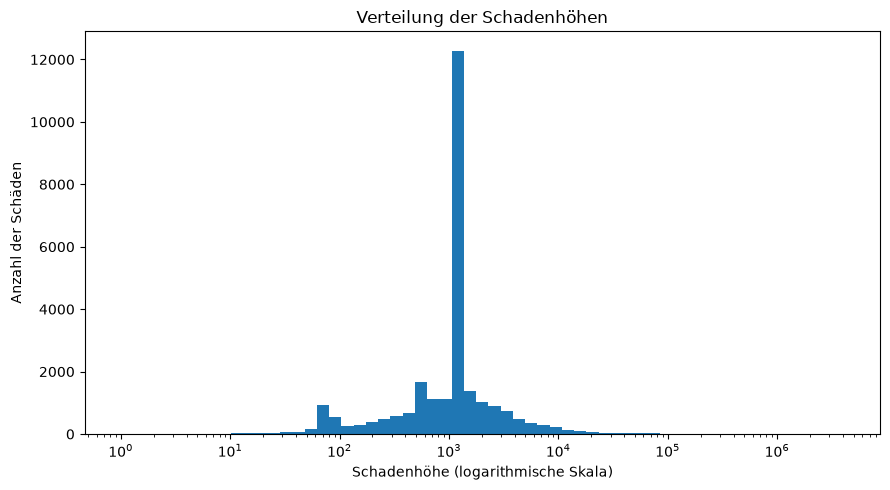

In [29]:
log_bins = np.logspace(
    np.log10(severity_df["ClaimAmount"].min()),
    np.log10(severity_df["ClaimAmount"].max()),
    60
)

plt.figure(figsize=(9, 5))

plt.hist(
    severity_df["ClaimAmount"],
    bins=log_bins
)

plt.xscale("log")
plt.title("Verteilung der Schadenhöhen")
plt.xlabel("Schadenhöhe (logarithmische Skala)")
plt.ylabel("Anzahl der Schäden")
plt.tight_layout()
plt.show()

**Ergebnis:** Die Schadenhöhen sind stark rechtsschief verteilt. Die meisten Schäden liegen im niedrigen bis mittleren Bereich, während wenige sehr hohe Schäden einen ausgeprägten rechten Rand erzeugen.

## 9. Beobachteter Pure Premium nach Segment

Der beobachtete Pure Premium wird für Policen mit verfügbarer Schadenhöhe segmentweise untersucht.

In [30]:
pure_premium_base = df[
    df["total_claim_amount"].notna()
].copy()

print("Policies used:", len(pure_premium_base))

Policies used: 668897


In [31]:
driver_age_pp = (
    pure_premium_base
    .groupby("driver_age_group", observed=True)
    .agg(
        policies=("IDpol", "count"),
        exposure=("Exposure", "sum"),
        claim_amount=("total_claim_amount", "sum"),
    )
)

driver_age_pp["observed_pure_premium"] = (
    driver_age_pp["claim_amount"]
    / driver_age_pp["exposure"]
)

driver_age_pp

,policies,exposure,claim_amount,observed_pure_premium
driver_age_group,,,,
18-24,29877,12376.881904,11741344.21,948.651227
25-34,139600,64097.447934,9957419.91,155.348149
35-44,168731,86576.318637,12284481.34,141.891935
45-54,161467,88488.887029,12569823.09,142.049737
55-64,97657,55349.510948,6697343.57,121.000953
65-74,49769,31499.213645,4123771.44,130.916647
75+,21796,15366.387934,2535032.94,164.972598


### Pure Premium nach Fahrer-Alter

Der beobachtete Pure Premium wird nach Fahrer-Altersgruppen grafisch verglichen.

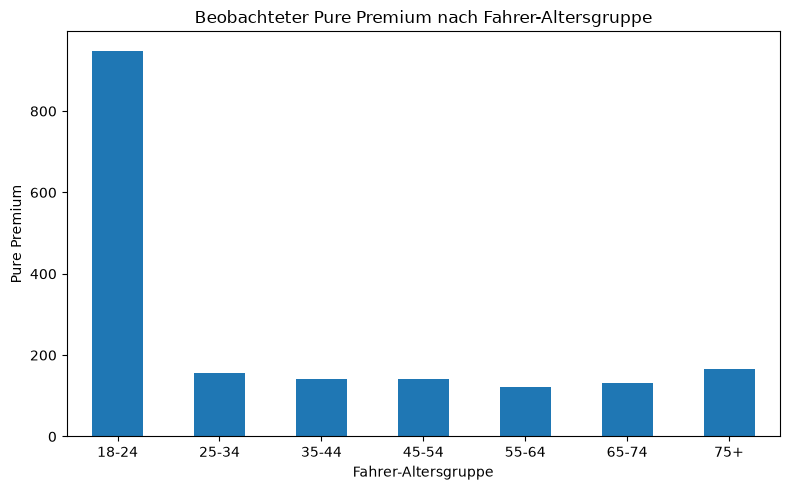

In [32]:
driver_age_pp["observed_pure_premium"].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Beobachteter Pure Premium nach Fahrer-Altersgruppe")
plt.xlabel("Fahrer-Altersgruppe")
plt.ylabel("Pure Premium")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Ergebnis:** Die Fahrergruppe 18–24 weist den mit Abstand höchsten beobachteten Pure Premium auf. Aufgrund der stark rechtsschiefen Schadenverteilung sollte geprüft werden, inwieweit einzelne Großschäden dieses Ergebnis beeinflussen.

### Pure Premium nach Bonus-Malus-Segment

Der beobachtete Pure Premium wird nach Bonus-Malus-Segmenten untersucht.

In [33]:
bonus_malus_pp = (
    pure_premium_base
    .groupby("bonus_malus_segment", observed=True)
    .agg(
        policies=("IDpol", "count"),
        exposure=("Exposure", "sum"),
        claim_amount=("total_claim_amount", "sum"),
    )
)

bonus_malus_pp["observed_pure_premium"] = (
    bonus_malus_pp["claim_amount"]
    / bonus_malus_pp["exposure"]
)

bonus_malus_pp

,policies,exposure,claim_amount,observed_pure_premium
bonus_malus_segment,,,,
50,378060,221650.852979,22282394.02,100.529250
51-64,123492,61930.186182,11153629.66,180.100051
65-79,69788,30942.909538,6609329.81,213.597555
80-99,70692,29556.272492,7116884.87,240.791016
100+,26865,9674.426840,12746978.14,1317.595176


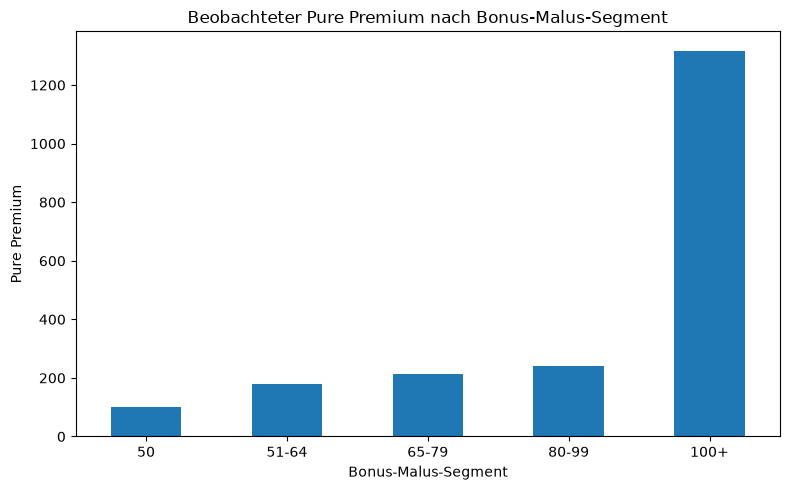

In [34]:
bonus_malus_pp["observed_pure_premium"].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Beobachteter Pure Premium nach Bonus-Malus-Segment")
plt.xlabel("Bonus-Malus-Segment")
plt.ylabel("Pure Premium")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Ergebnis:** Mit steigenden Bonus-Malus-Werten nimmt auch der beobachtete Pure Premium deutlich zu. Das Segment 100+ weist einen besonders hohen Wert auf.

## 10. Zentrale Portfoliokennzahlen

Die wichtigsten tatsächlichen Kennzahlen des Datenbestands werden dokumentiert.

In [35]:
total_policies = len(df)

claim_free_policies = (df["ClaimNb"] == 0).sum()
claim_policies = (df["ClaimNb"] > 0).sum()

claim_free_rate = (
    claim_free_policies / total_policies
)

severity_rows = len(severity_df)

matched_severity_rows = (
    severity_df["IDpol"]
    .isin(df["IDpol"])
    .sum()
)

severity_matching_rate = (
    matched_severity_rows / severity_rows
)

print(f"Policys gesamt: {total_policies:,}")
print(f"Schadenfreie Policen: {claim_free_policies:,}")
print(f"Anteil schadenfreier Policen: {claim_free_rate:.2%}")
print(f"Policen mit ClaimNb > 0: {claim_policies:,}")
print(f"Severity-Zeilen: {severity_rows:,}")
print(f"Gematchte Severity-Zeilen: {matched_severity_rows:,}")
print(f"Matching-Quote: {severity_matching_rate:.2%}")

Policys gesamt: 678,013
Schadenfreie Policen: 643,953
Anteil schadenfreier Policen: 94.98%
Policen mit ClaimNb > 0: 34,060
Severity-Zeilen: 26,639
Gematchte Severity-Zeilen: 26,444
Matching-Quote: 99.27%


### Abdeckung der Severity-Informationen

Zusätzlich wird geprüft, für welchen Anteil der Schadenpolicen Severity-Informationen verfügbar sind.

In [36]:
claim_policies_with_severity = (
    (df["ClaimNb"] > 0)
    & (~df["missing_severity"])
).sum()

severity_policy_coverage = (
    claim_policies_with_severity
    / claim_policies
)

print(
    f"Schadenpolicen mit Severity: "
    f"{claim_policies_with_severity:,}"
)

print(
    f"Severity-Abdeckung bei Schadenpolicen: "
    f"{severity_policy_coverage:.2%}"
)

Schadenpolicen mit Severity: 24,944
Severity-Abdeckung bei Schadenpolicen: 73.24%


**Ergebnis:** 99,27 % der Severity-Zeilen lassen sich einer Policy zuordnen. Gleichzeitig sind Severity-Informationen nur für 73,24 % der Schadenpolicen verfügbar. Die beiden Kennzahlen messen daher unterschiedliche Aspekte der Datenqualität.

## 11. Korrelationsanalyse

Die numerischen Risikomerkmale werden mit der Spearman-Korrelation untersucht. Abgeleitete Zielgrößen werden bewusst ausgeschlossen, um künstliche Zusammenhänge zu vermeiden.

In [37]:
correlation_columns = [
    "Exposure",
    "VehPower",
    "VehAge",
    "DrivAge",
    "BonusMalus",
    "Density",
    "log_density",
    "ClaimNb",
]

spearman_corr = (
    df[correlation_columns]
    .corr(method="spearman")
)

spearman_corr.round(2)

,Exposure,VehPower,VehAge,DrivAge,BonusMalus,Density,log_density,ClaimNb
Exposure,1.00,-0.04,0.18,0.16,-0.20,-0.12,-0.12,0.07
VehPower,-0.04,1.00,-0.00,0.04,-0.07,-0.01,-0.01,-0.00
VehAge,0.18,-0.00,1.00,-0.08,0.08,-0.10,-0.10,-0.02
DrivAge,0.16,0.04,-0.08,1.00,-0.57,-0.04,-0.04,0.01
BonusMalus,-0.20,-0.07,0.08,-0.57,1.00,0.14,0.14,0.04
Density,-0.12,-0.01,-0.10,-0.04,0.14,1.00,1.00,0.01
log_density,-0.12,-0.01,-0.10,-0.04,0.14,1.00,1.00,0.01
ClaimNb,0.07,-0.00,-0.02,0.01,0.04,0.01,0.01,1.00


### Spearman-Korrelationsmatrix

Die Zusammenhänge zwischen den numerischen Merkmalen werden als Heatmap dargestellt.

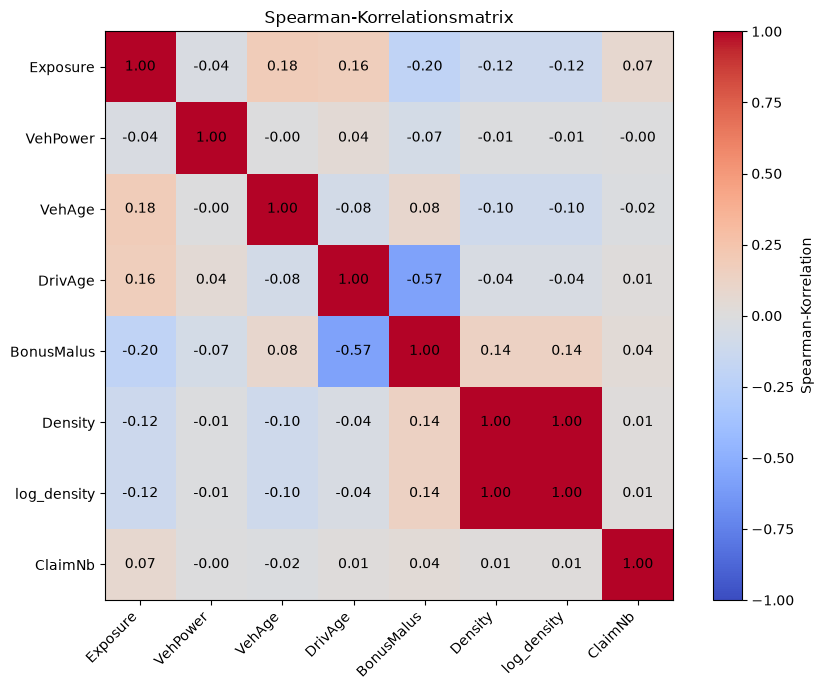

In [38]:
fig, ax = plt.subplots(figsize=(9, 7))

heatmap = ax.imshow(
    spearman_corr,
    vmin=-1,
    vmax=1,
    cmap="coolwarm"
)

ax.set_xticks(range(len(spearman_corr.columns)))
ax.set_yticks(range(len(spearman_corr.columns)))

ax.set_xticklabels(
    spearman_corr.columns,
    rotation=45,
    ha="right"
)
ax.set_yticklabels(spearman_corr.columns)

for i in range(len(spearman_corr.columns)):
    for j in range(len(spearman_corr.columns)):
        ax.text(
            j,
            i,
            f"{spearman_corr.iloc[i, j]:.2f}",
            ha="center",
            va="center"
        )

plt.colorbar(
    heatmap,
    ax=ax,
    label="Spearman-Korrelation"
)

plt.title("Spearman-Korrelationsmatrix")
plt.tight_layout()
plt.show()

**Ergebnis:** Die meisten numerischen Merkmale weisen nur geringe paarweise Korrelationen auf. Auffällig ist insbesondere die negative Beziehung zwischen Fahrer-Alter und Bonus-Malus. Density und log_density sind aufgrund der monotonen Transformation vollständig rangkorreliert. Die niedrigen Korrelationen mit ClaimNb bedeuten nicht automatisch eine geringe Risikorelevanz, da Schadenanzahl und Exposure-Struktur berücksichtigt werden müssen.

## 12. Verteilung der Schadenanzahl

Die Verteilung von ClaimNb wird untersucht, um die starke Konzentration schadenfreier Policen sichtbar zu machen.

In [39]:
claim_count_distribution = (
    df["ClaimNb"]
    .value_counts()
    .sort_index()
    .rename_axis("ClaimNb")
    .to_frame("policies")
)

claim_count_distribution["share"] = (
    claim_count_distribution["policies"]
    / len(df)
)

claim_count_distribution

,policies,share
ClaimNb,,
0,643953,0.949765
1,32178,0.047459
2,1784,0.002631
3,82,0.000121
4,7,0.000010
5,2,0.000003
6,1,0.000001
8,1,0.000001
9,1,0.000001


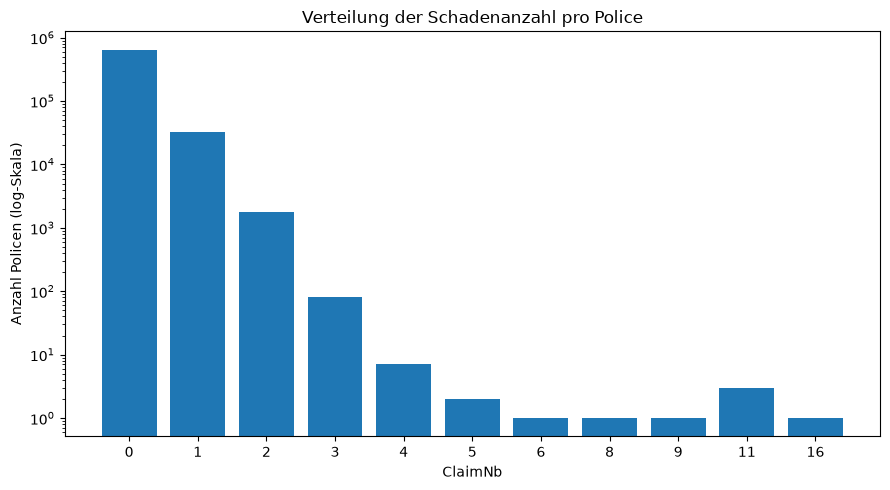

In [40]:
plt.figure(figsize=(9, 5))

plt.bar(
    claim_count_distribution.index.astype(str),
    claim_count_distribution["policies"]
)

plt.yscale("log")

plt.title("Verteilung der Schadenanzahl pro Police")
plt.xlabel("ClaimNb")
plt.ylabel("Anzahl Policen (log-Skala)")
plt.tight_layout()
plt.show()

**Ergebnis:** Die Schadenanzahl ist stark auf null konzentriert: 94,98 % der Policen weisen keinen Schaden auf. Mit steigender Schadenanzahl nimmt die Anzahl der Policen sehr schnell ab. Diese stark unbalancierte Count-Verteilung ist für die spätere Frequenzmodellierung besonders relevant.

## 13. Verteilung der Exposure

Die Verteilung der Exposure wird untersucht, da sie für die annualisierte Schadenfrequenz und die spätere Modellgewichtung zentral ist.

In [41]:
exposure_summary = df["Exposure"].describe(
    percentiles=[
        0.10,
        0.25,
        0.50,
        0.75,
        0.90,
        0.95,
        0.99,
    ]
)

exposure_summary

count    678013.000000
mean          0.528545
std           0.364081
min           0.002732
10%           0.070000
25%           0.180000
50%           0.490000
75%           0.990000
90%           1.000000
95%           1.000000
99%           1.000000
max           1.000000
Name: Exposure, dtype: float64

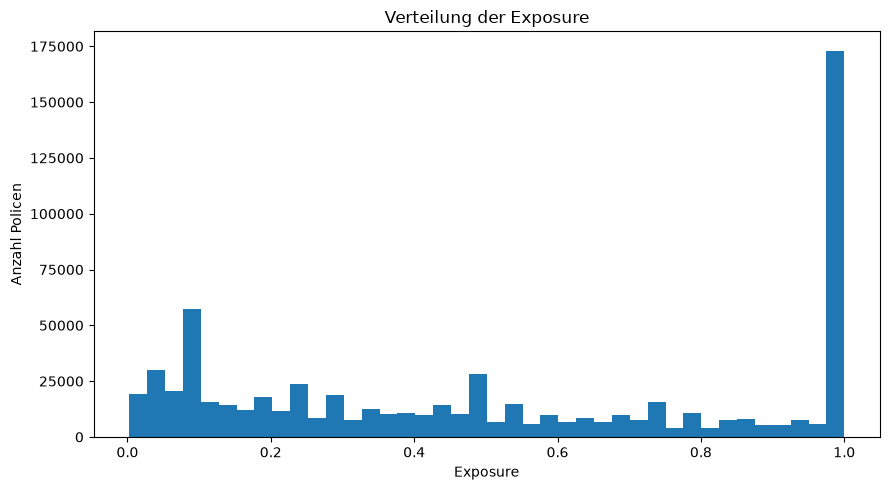

In [42]:
plt.figure(figsize=(9, 5))

plt.hist(
    df["Exposure"],
    bins=40
)

plt.title("Verteilung der Exposure")
plt.xlabel("Exposure")
plt.ylabel("Anzahl Policen")
plt.tight_layout()
plt.show()

**Ergebnis:** Die Exposure ist breit zwischen sehr kurzen Beobachtungszeiten und einem vollständigen Versicherungsjahr verteilt. Ein großer Anteil der Policen liegt bei Exposure = 1. Für die spätere Frequenzmodellierung muss die unterschiedliche Beobachtungsdauer deshalb ausdrücklich berücksichtigt werden.

## 14. Fazit

Die explorative Analyse zeigt deutliche Risikounterschiede innerhalb des Portfolios. Besonders junge Fahrer, hohe Bonus-Malus-Werte sowie dichter besiedelte Gebiete weisen erhöhte Schadenhäufigkeiten auf.

Die Schadenhöhen sind stark rechtsschief verteilt und werden durch wenige Großschäden beeinflusst. Gleichzeitig ist die Schadenanzahl stark auf null konzentriert, und die unterschiedliche Exposure-Dauer muss bei der Frequenzmodellierung berücksichtigt werden.

Die Korrelationsanalyse zeigt überwiegend geringe paarweise Zusammenhänge zwischen den Risikomerkmalen. Die gewonnenen Erkenntnisse bilden damit eine fundierte Grundlage für die anschließende Modellierung.